# Práctica 1: Predicción Multiclase de Riesgo Cardiovascular en Población Adulta

## Planteamiento del problema

Las enfermedades cardiovasculares continúan siendo una de las mayores amenazas para la salud pública global y una de las principales causas de morbimortalidad a nivel mundial. Para combatir este problema, la detección temprana y la estratificación precisa del nivel de riesgo individual son pilares esenciales que permiten aplicar intervenciones preventivas adaptadas a cada paciente y optimizar la gestión de los recursos en los sistemas de salud.

Conscientes de esta necesidad, el equipo médico e investigador del **Hospital Morales Meseguer** ha puesto en marcha un proyecto estratégico orientado al desarrollo de herramientas predictivas de vanguardia. La iniciativa nace con el objetivo de ofrecer una solución integral basada en datos clínicos que transforme la evaluación del riesgo cardiovascular en la práctica médica diaria, mejorando directamente el diagnóstico y el seguimiento del paciente. Para ello, el equipo médico pone a disposición de este proyecto una cohorte clínica con 2.254 registros de pacientes y 28 variables sociodemográficas, clínicas, analíticas y de estilo de vida para clasificar a los pacientes en tres niveles de riesgo cardiovascular (**Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo**).

## Requisitos técnicos e instalación de librerías necesarias

Para reproducir el proyecto se recomienda crear un entorno virtual e instalar las versiones exactas de `requirements.txt`:

```bash
python -m venv .venv
# Windows: .venv\Scripts\activate   |   Linux/Mac: source .venv/bin/activate
pip install -r requirements.txt
```

## Implementación

### Librerías a importar

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Semilla para que todo sea reproducible
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

### Carga de la base de datos (csv)

In [2]:
# Cargamos el dataset 
original_dataset = pd.read_csv("enfermedad_cardiovascular.csv", encoding="UTF-8")

print(f"Dimensiones: {original_dataset.shape}")
# Mostramos las primeras 5 filas
original_dataset.head()

Dimensiones: (2254, 28)


,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,6.7,-4.9,5.5,NaN,10.13,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0


### 1. Análisis exploratorio de datos e identificación de problemáticas

#### 1.1. Estructura general del dataset

Separamos las variables por tipo según el diccionario del enunciado: numéricas continuas, binarias (0/1) y nominales. Trabajamos sobre una copia para no tocar el dataset original.

In [3]:
df = original_dataset.copy()

target = "riesgo_cardiovascular"
vars_binarias = ["fumador_actual", "hipertension_previa", "diabetes_mellitus",
                 "tratamiento_estatinas", "uso_antihipertensivos"]
vars_categoricas = ["tipo_alimentacion", "nivel_actividad", "antecedentes_familiares_tipo"]
vars_numericas = [c for c in df.columns if c not in vars_binarias + vars_categoricas + [target]]

print(f"Numéricas: {len(vars_numericas)} | Binarias: {len(vars_binarias)} | Categóricas: {len(vars_categoricas)}")
df.info()

Numéricas: 19 | Binarias: 5 | Categóricas: 3
<class 'pandas.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                

#### 1.2. Variable objetivo

,n,%
riesgo_cardiovascular,,
0,1127,50.0
1,676,30.0
2,451,20.0


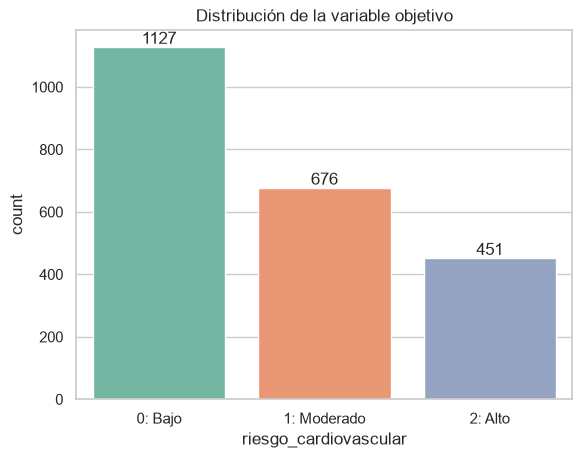

Ratio clase mayoritaria / minoritaria: 2.50


In [4]:
conteo = df[target].value_counts().sort_index()
porcentaje = (conteo / len(df) * 100).round(1)
display(pd.DataFrame({"n": conteo, "%": porcentaje}))

ax = sns.countplot(x=target, data=df, hue=target, palette="Set2", legend=False)
ax.set_xticks([0, 1, 2], ["0: Bajo", "1: Moderado", "2: Alto"])
ax.set_title("Distribución de la variable objetivo")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

print(f"Ratio clase mayoritaria / minoritaria: {conteo.max() / conteo.min():.2f}")

**Observación:** las clases están desbalanceadas (≈50% / 30% / 20%). La clase de alto riesgo, que es la más importante desde el punto de vista clínico, es la minoritaria. Esto habrá que tenerlo en cuenta en la partición (estratificada), en las métricas (no basta con accuracy) y en el preprocesado.

#### 1.3. Valores nulos y duplicados

In [5]:
nulos = df.isna().sum()
nulos = pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
display(nulos[nulos["nulos"] > 0])

print(f"Filas con al menos un nulo: {df.isna().any(axis=1).sum()} ({df.isna().any(axis=1).mean() * 100:.1f}%)")
print(f"Filas duplicadas: {df.duplicated().sum()}")

,nulos,%
colesterol_ldl,135,5.99
glucosa_ayunas,112,4.97
horas_sueno_diarias,180,7.99
proteina_c_reactiva,157,6.97


Filas con al menos un nulo: 533 (23.6%)
Filas duplicadas: 0


In [6]:
# ¿Los nulos dependen de la clase? Si fuera así no serían aleatorios
cols_nulos = nulos[nulos["nulos"] > 0].index
(df[cols_nulos].isna().groupby(df[target]).mean() * 100).round(2)

,colesterol_ldl,glucosa_ayunas,horas_sueno_diarias,proteina_c_reactiva
riesgo_cardiovascular,,,,
0,6.39,4.44,8.25,8.16
1,6.07,4.59,7.69,5.77
2,4.88,6.87,7.76,5.76


**Observación:** hay 4 variables con nulos (`colesterol_ldl`, `glucosa_ayunas`, `horas_sueno_diarias` y `proteina_c_reactiva`), entre un 5% y un 8% en cada una. En total afectan a casi una cuarta parte de las filas, así que eliminarlas no es buena opción. El porcentaje de nulos es parecido en las tres clases, lo que apunta a que faltan de forma aleatoria (MCAR/MAR), por lo que tiene sentido imputar. No hay filas duplicadas.

#### 1.4. Estadísticos descriptivos

In [7]:
desc = df[vars_numericas].describe().T
desc["skew"] = df[vars_numericas].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
edad,2254.0,56.69,14.45,9.80,47.20,56.90,66.47,103.50,-0.03
presion_sistolica,2254.0,132.32,26.93,52.20,115.30,129.65,143.90,231.36,1.29
presion_diastolica,2254.0,82.17,13.08,30.80,73.60,82.10,91.10,122.50,-0.03
colesterol_total,2254.0,228.13,62.73,61.10,188.20,221.20,252.50,448.59,1.29
colesterol_hdl,2254.0,47.23,15.99,-8.80,36.70,47.30,58.20,106.30,-0.00
colesterol_ldl,2119.0,135.64,36.73,6.10,111.40,135.50,161.40,266.70,-0.05
trigliceridos,2254.0,176.66,72.74,-35.70,133.05,170.00,208.10,452.70,1.32
glucosa_ayunas,2142.0,104.11,24.94,32.00,86.30,103.75,120.48,194.00,0.12
indice_masa_corporal,2254.0,28.09,6.47,3.60,23.80,28.00,32.50,50.60,0.01
frecuencia_cardiaca_reposo,2254.0,73.67,12.76,25.80,65.00,73.10,82.30,112.70,-0.03


In [8]:
df[vars_categoricas + vars_binarias].astype(str).describe().T

,count,unique,top,freq
tipo_alimentacion,2254,4,Occidental,881
nivel_actividad,2254,4,Ligeramente activo,695
antecedentes_familiares_tipo,2254,4,Ninguno,1072
fumador_actual,2254,2,0,1659
hipertension_previa,2254,2,0,1427
diabetes_mellitus,2254,2,0,1741
tratamiento_estatinas,2254,2,0,1641
uso_antihipertensivos,2254,2,0,1467


**Observación:** ya en los descriptivos aparecen mínimos y máximos que no tienen sentido clínico (HDL y triglicéridos negativos, consumo de alcohol negativo, IMC de 3.6, edad mínima de 9.8 años en una cohorte de adultos, más de 7 días de ejercicio por semana...). También hay variables con asimetría positiva marcada (`colesterol_total`, `presion_sistolica`, `trigliceridos`, `acido_urico`, `proteina_c_reactiva`). Lo analizamos en detalle más abajo.

#### 1.5. Distribuciones

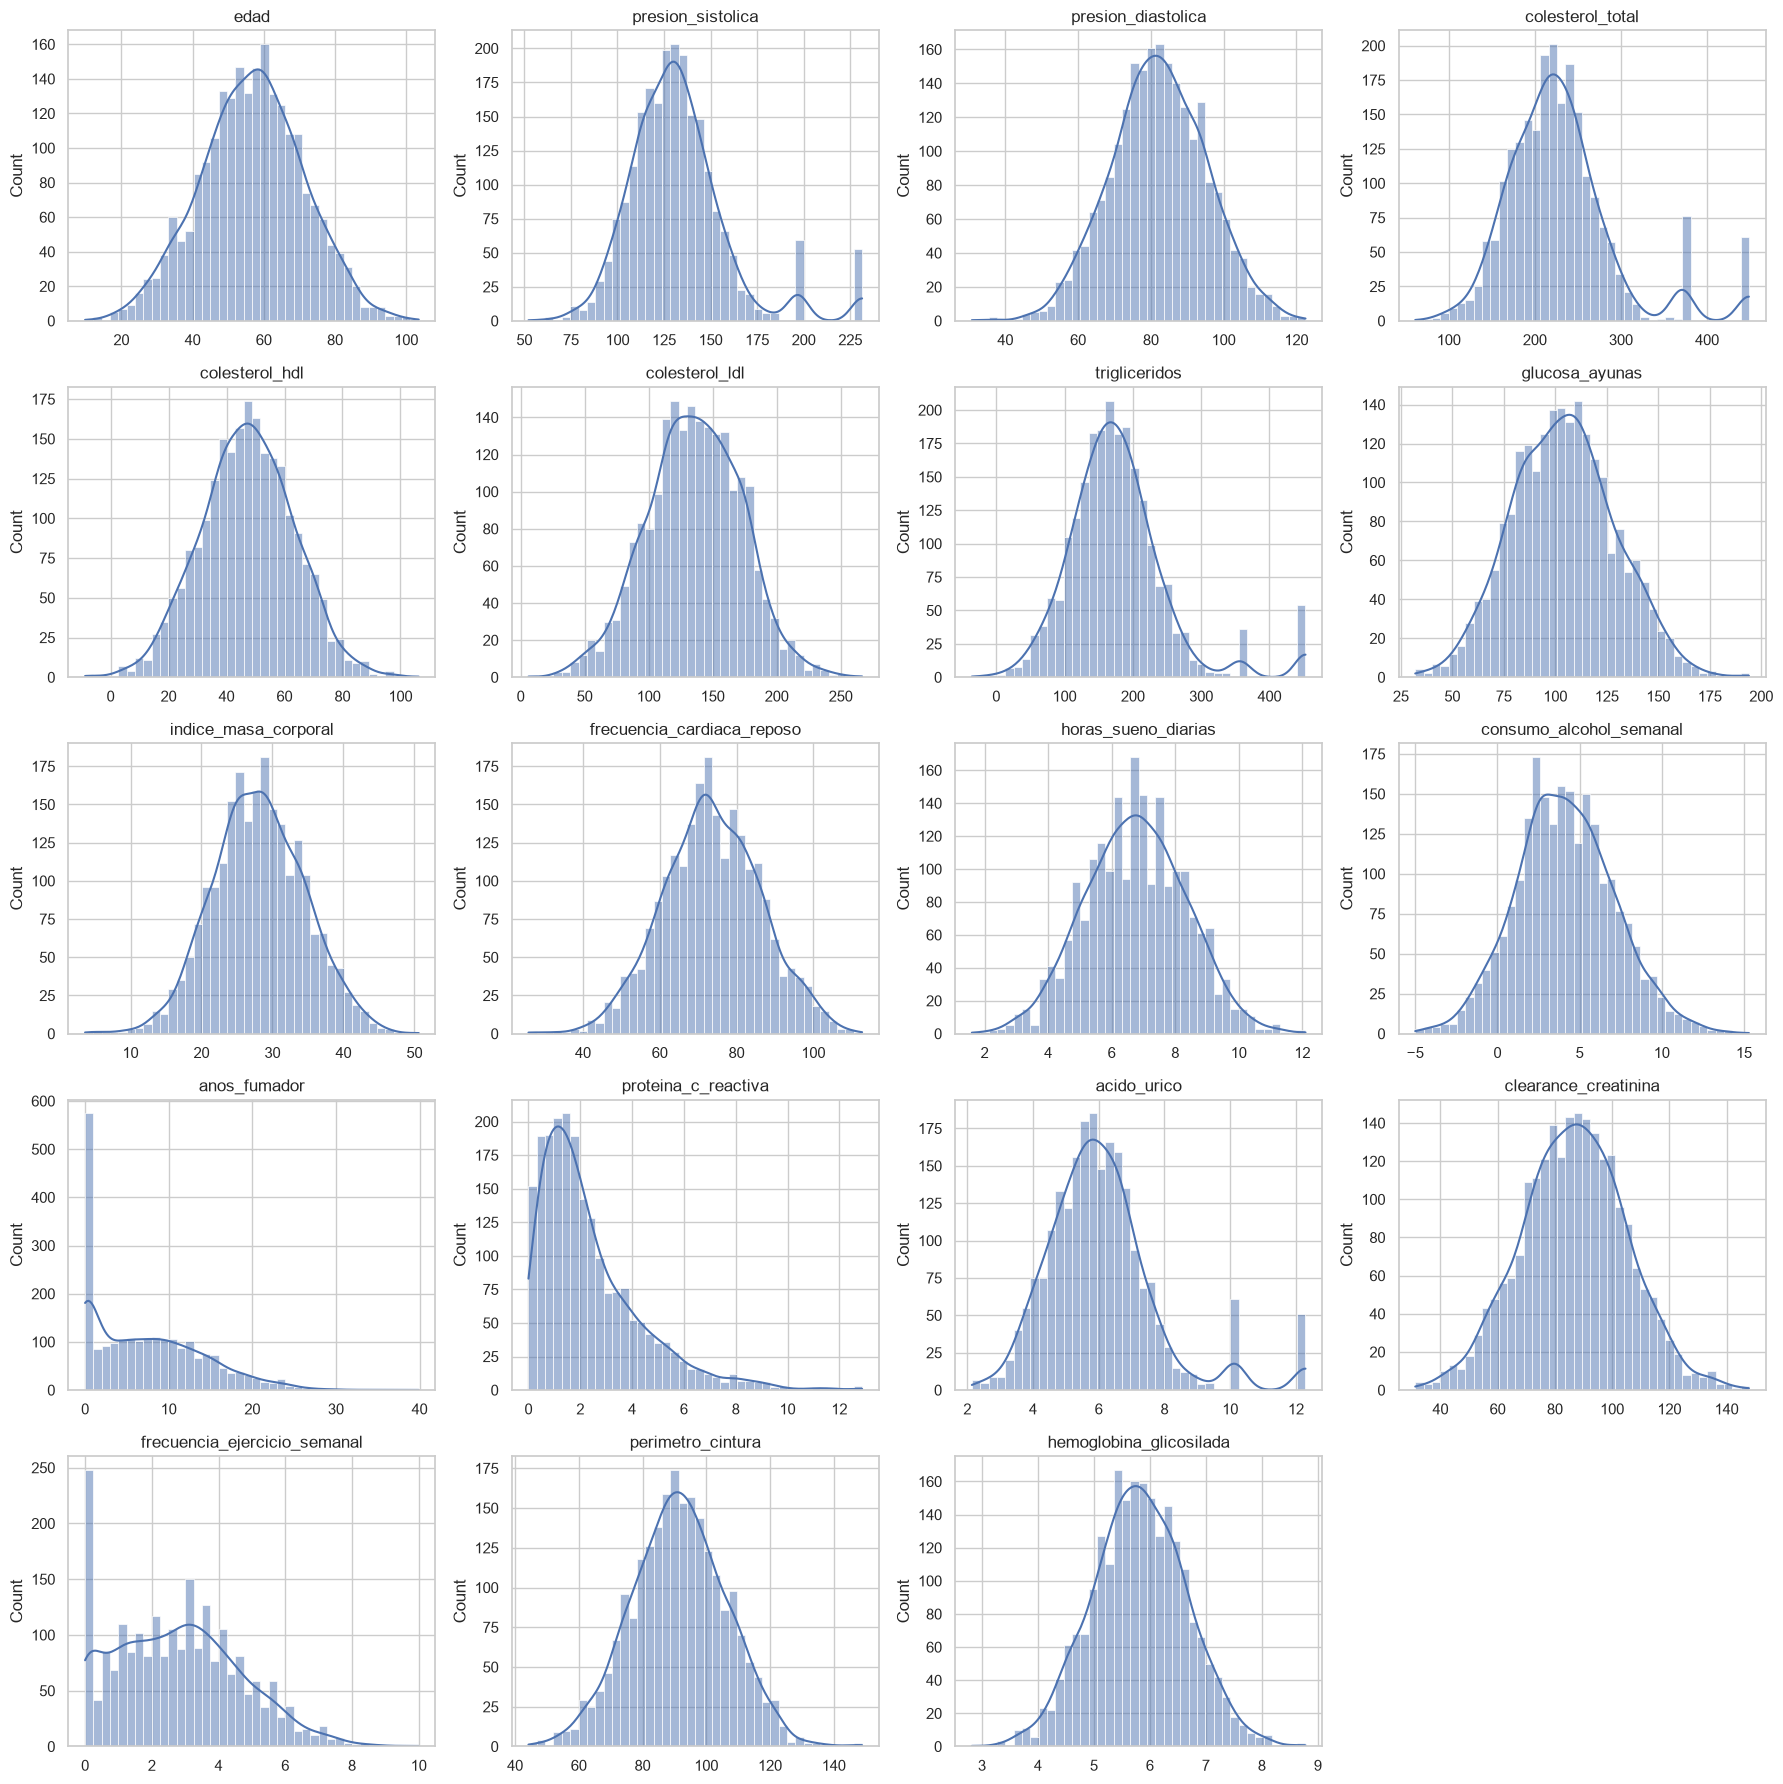

In [9]:
fig, axes = plt.subplots(5, 4, figsize=(18, 18))
for ax, col in zip(axes.flat, vars_numericas):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(vars_numericas):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

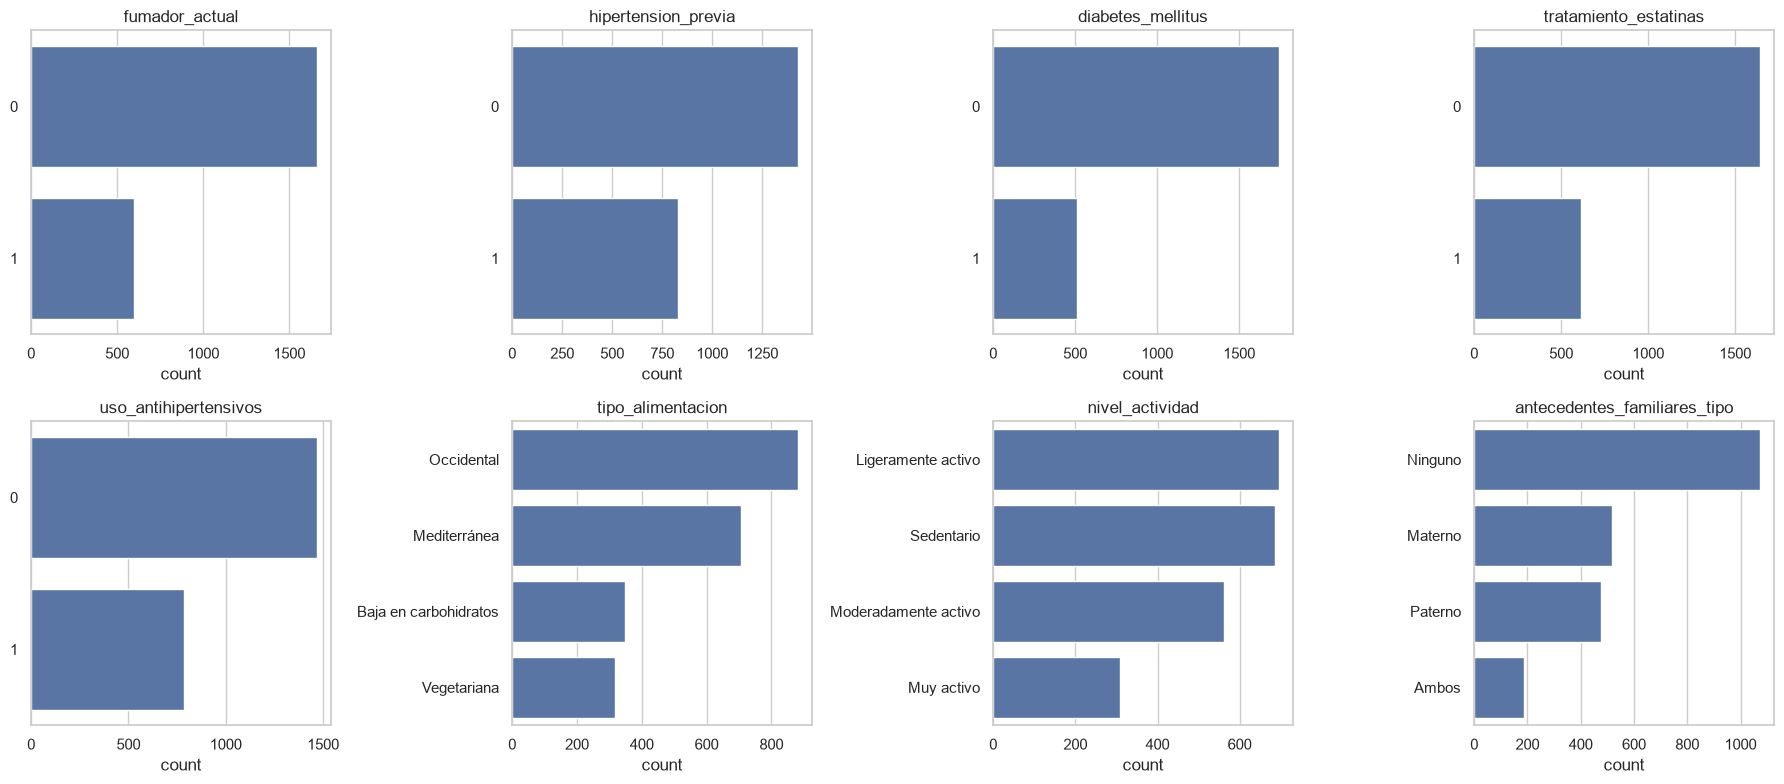

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, vars_binarias + vars_categoricas):
    orden = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=orden, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Observación:** la mayoría de numéricas tienen forma aproximadamente normal, pero en varias se ven **picos aislados en la cola derecha** (sistólica, colesterol total, triglicéridos y ácido úrico). Esos picos no son naturales y los estudiamos en el siguiente apartado. Las categóricas no tienen categorías raras ni mal escritas, aunque algunas están poco representadas (p. ej. `antecedentes_familiares_tipo = Ambos`).

### 2. Preprocesamiento de datos

### 3. Modelos

### 4. Estrategia de evaluación y métricas de rendimiento

### 5. Test estadísticos

## Conclusiones